# Problem 1: Rock–Paper–Scissors Classification

A Rock / Paper / Scissors image classifier trained with **Teachable Machine** (https://teachablemachine.withgoogle.com/), loaded in Python and used for inference.

**Steps**
1. Load the trained Teachable Machine model (`model/keras_model.h5`) and its labels (`model/labels.txt`)
2. Accept a new image as input
3. Pre-process it the same way Teachable Machine does (224×224 RGB, pixels scaled to [-1, 1])
4. Run forward propagation (inference) through the network
5. Classify the image as Rock, Paper, or Scissors

The code lives in `rock_paper_scissors.py` (class `RockPaperScissors`); this notebook walks through it.

## 0. Setup
Teachable Machine exports a Keras 2 `.h5` model. With TensorFlow ≥ 2.16 install the `tf-keras` package so it can be read: `pip install tensorflow tf-keras`.

In [9]:
%pip install tensorflow tf-keras numpy pillow matplotlib

Note: you may need to restart the kernel to use updated packages.


In [10]:
import os, glob
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'   # hide TensorFlow info messages
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

from rock_paper_scissors import RockPaperScissors

print('TensorFlow', tf.__version__)
np.set_printoptions(precision=4, suppress=True)

TensorFlow 2.21.0


## 1. Load the trained Teachable Machine model

In [11]:
rps = RockPaperScissors('model/keras_model.h5', 'model/labels.txt')
print('Classes:', rps.labels)
print('Input shape :', rps.model.input_shape)
print('Output shape:', rps.model.output_shape)
rps.model.summary()

Classes: ['Rock', 'Paper', 'Scissor']
Input shape : (None, 224, 224, 3)
Output shape: (None, 3)
Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential_1 (Sequential)   (None, 1280)              410208    
                                                                 
 sequential_3 (Sequential)   (None, 3)                 128400    
                                                                 
Total params: 538608 (2.05 MB)
Trainable params: 524528 (2.00 MB)
Non-trainable params: 14080 (55.00 KB)
_________________________________________________________________


## 2. Accept a new image as input
Change `IMAGE_PATH` to any photo of your hand (it does not need to be one of the training images).

rps_images\paper_1.jpg (1920, 1080) RGB


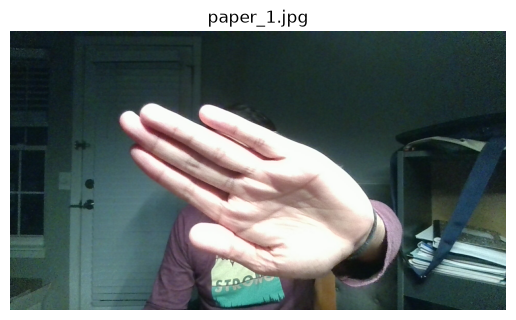

In [12]:
IMAGE_PATH = sorted(glob.glob('rps_images/*'))[0]   # or e.g. 'rps_images/my_rock.jpg'
image = Image.open(IMAGE_PATH)
print(IMAGE_PATH, image.size, image.mode)
plt.imshow(image)
plt.title(os.path.basename(IMAGE_PATH))
plt.axis('off')
plt.show()

## 3. Pre-processing
Center-crop and resize to 224×224, convert to RGB, scale each pixel with `x / 127.5 - 1` so values are in [-1, 1], and add a batch dimension.

input tensor shape: (1, 224, 224, 3)
value range       : [-1.000, 1.000]


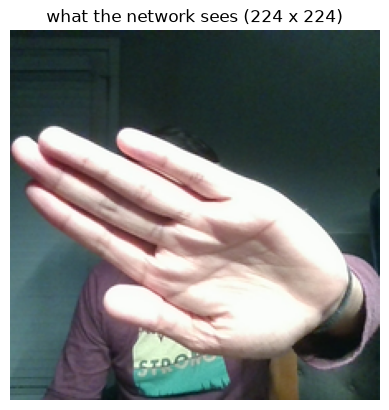

In [13]:
x, resized = rps.preprocess(image)
print('input tensor shape:', x.shape)
print('value range       : [%.3f, %.3f]' % (x.min(), x.max()))
plt.imshow(resized)
plt.title('what the network sees (224 x 224)')
plt.axis('off')
plt.show()

## 4. Forward propagation
The Teachable Machine model has two blocks: a MobileNet feature extractor (convolutions → a feature vector) followed by a small dense classifier ending in softmax. Below the input is pushed through the blocks one at a time, and the result is compared with a single call to the whole model.

In [14]:
y_steps = rps.forward_layer_by_layer(x)
y_model = rps.forward(x)
print('\nsoftmax output (layer by layer):', y_steps[0])
print('softmax output (whole model)   :', y_model[0])
print('same result:', np.allclose(y_steps, y_model, atol=1e-5))
print('probabilities sum to', y_model[0].sum())

model1                       Functional               -> output shape (1, 7, 7, 1280)
global_average_pooling2d_GlobalAveragePooling2D1 GlobalAveragePooling2D   -> output shape (1, 1280)
dense_Dense1                 Dense                    -> output shape (1, 100)
dense_Dense2                 Dense                    -> output shape (1, 3)

softmax output (layer by layer): [0.     0.9819 0.018 ]
softmax output (whole model)   : [0.     0.9819 0.018 ]
same result: True
probabilities sum to 0.99999994


## 5. Classify the image

Prediction: Paper  (confidence 98.2%)


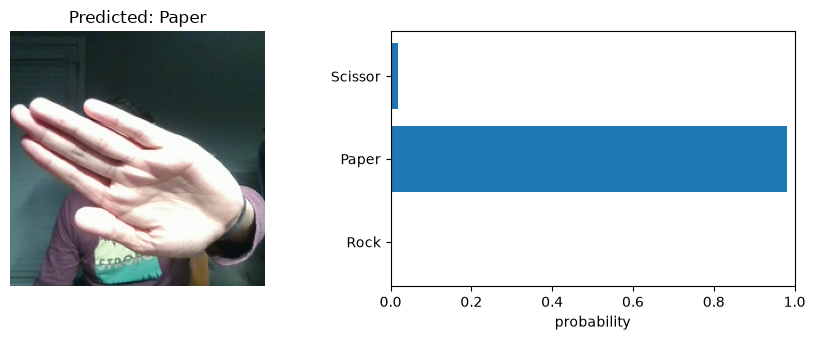

In [15]:
label, conf, probs, _ = rps.predict(IMAGE_PATH)
print(f'Prediction: {label}  (confidence {conf:.1%})')

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].imshow(resized); ax[0].set_title(f'Predicted: {label}'); ax[0].axis('off')
ax[1].barh(rps.labels, probs)
ax[1].set_xlim(0, 1); ax[1].set_xlabel('probability')
plt.tight_layout(); plt.show()

## 6. Classify every image in `rps_images/`

paper_1.jpg               -> Paper     (98.2%)
rock_1.jpg                -> Rock      (97.6%)
scissor_1.jpg             -> Scissor   (99.9%)


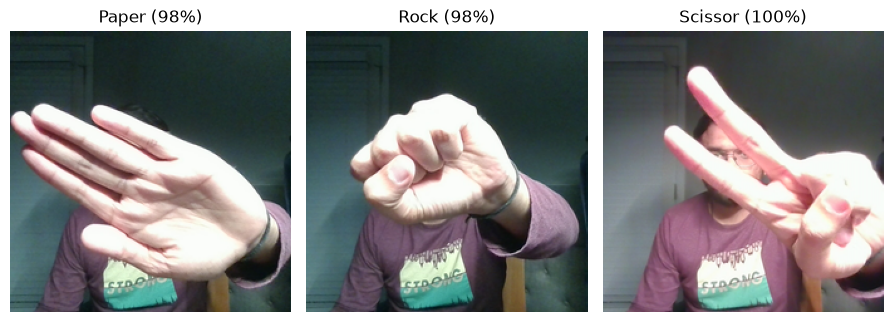

In [16]:
paths = sorted(glob.glob('rps_images/*'))
cols = 4
rows = int(np.ceil(len(paths) / cols))
plt.figure(figsize=(3 * cols, 3.2 * rows))
for i, p in enumerate(paths):
    label, conf, probs, resized = rps.predict(p)
    print(f'{os.path.basename(p):25s} -> {label:9s} ({conf:.1%})')
    plt.subplot(rows, cols, i + 1)
    plt.imshow(resized)
    plt.title(f'{label} ({conf:.0%})')
    plt.axis('off')
plt.tight_layout(); plt.show()